<div style="background:#0B2545;color:white;padding:18px 22px;border-radius:8px">
<div style="font-size:12px;letter-spacing:2px;opacity:.8">DATABANK ACADEMY · PROGRAMA EJECUTIVO EN GESTIÓN INTEGRAL DEL RIESGO DE CRÉDITO MINORISTA</div>
<div style="font-size:24px;font-weight:700;margin-top:6px">Módulo 2 · Sesión 2: Muestra, estimadores, intervalos y teoremas límite</div>
<div style="font-size:14px;margin-top:4px;opacity:.9">Laboratorio: sesgo y varianza, shrinkage, IC para PD, diferencias y LGD, tamaño de muestra, LGN, TLC y bootstrap</div>
</div>

## Objetivos de la sesión (2 horas)

1. Distinguir **población, muestra, parámetro y estimador**, y medir **sesgo, varianza y error cuadrático medio**.
2. Construir **intervalos de confianza** para una PD (Wald, Wilson, Clopper-Pearson, Jeffreys), para la **diferencia de dos PDs** y para una **LGD promedio**.
3. Calcular el **tamaño de muestra** necesario para estimar una PD con una precisión dada.
4. Comprobar con simulación las **distribuciones muestrales**, la **ley de los grandes números** y el **teorema central del límite**.
5. Medir incertidumbre sin fórmula con **bootstrap**.

| Bloque | Tiempo | Contenido |
|---|---|---|
| 1 | 20 min | Población, muestra, estimadores y shrinkage |
| 2 | 25 min | Intervalos de confianza para una PD |
| 3 | 30 min | Distribuciones muestrales, LGN, TLC y bootstrap |
| 4 | 20 min | Intervalos para diferencias de PDs y para la LGD |
| 5 | 15 min | Tamaño de muestra |
| 6 | 10 min | Ejercicios |

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from pathlib import Path
pd.set_option("display.float_format", lambda x: f"{x:,.4f}")
plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": .3, "font.size": 11})
AZUL, ROJO, VERDE, GRIS, ORO = "#0B2545", "#C8102E", "#2E8B57", "#8D99AE", "#E0A100"
DATA = Path("../datos")

from scipy import stats, optimize
import statsmodels.api as sm
from statsmodels.stats.proportion import proportion_confint
app = pd.read_csv(DATA / "hc_application_sintetico.csv")
german = pd.read_csv(DATA / "german_credit.csv")
rng = np.random.default_rng(2027)

## 1. Población, muestra y estimadores
Tratemos las 60 mil solicitudes como la **población** (PD verdadera $p$) y extraigamos **muestras** como las que tendría un analista con poca historia.

- **Estimador** de la PD: $\hat p = \frac{1}{n}\sum D_i$ (la tasa de incumplimiento observada).
- **Sesgo:** $E[\hat p] - p$. **Varianza:** $\text{Var}(\hat p) = p(1-p)/n$. **ECM** = sesgo² + varianza.

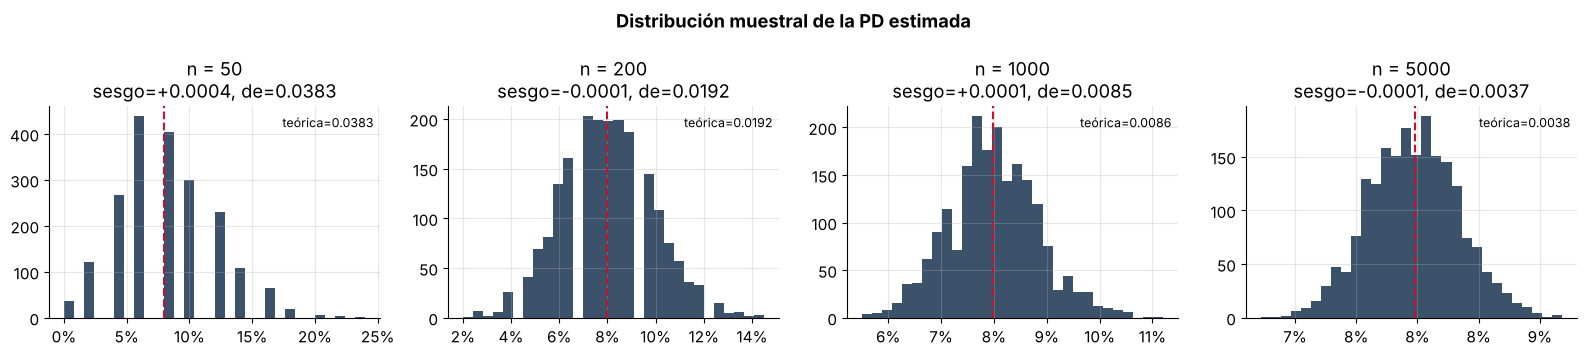

In [2]:
p_pob = app.TARGET.mean()
tamanos = [50, 200, 1000, 5000]
fig, ax = plt.subplots(1, 4, figsize=(16, 3.6), sharey=False)
for a, n in zip(ax, tamanos):
    est = np.array([app.TARGET.sample(n, random_state=int(s)).mean() for s in rng.integers(0, 1e9, 2000)])
    a.hist(est, bins=30, color=AZUL, alpha=.8); a.axvline(p_pob, color=ROJO, ls="--")
    a.set_title(f"n = {n}\nsesgo={est.mean() - p_pob:+.4f}, de={est.std():.4f}"); a.xaxis.set_major_formatter(plt.FuncFormatter(lambda y, _: f"{y:.0%}"))
    a.text(0.98, 0.9, f"teórica={np.sqrt(p_pob * (1 - p_pob) / n):.4f}", transform=a.transAxes, ha="right", fontsize=9)
fig.suptitle("Distribución muestral de la PD estimada", weight="bold"); plt.tight_layout(); plt.show()

**Un estimador sesgado pero útil:** en segmentos con pocos datos se suele "encoger" la PD hacia la media de la cartera (*shrinkage*):
$$\hat p_{shrink} = \frac{n}{n + k}\hat p + \frac{k}{n + k}\, \bar p$$
Tiene **sesgo**, pero mucha menos **varianza**. Es la misma idea que reaparece en la regularización (Módulo 3), en las *target statistics* de CatBoost (Módulo 5) y en Bayes (Módulo 6).

In [3]:
# Segmento chico con PD verdadera 15 %: ¿quién estima mejor, la tasa cruda o la "encogida"?
p_seg, n, k, sims = 0.15, 40, 30, 20000
crudo = rng.binomial(n, p_seg, sims) / n
shrink = n / (n + k) * crudo + k / (n + k) * p_pob
for nombre, e in [("Tasa cruda", crudo), ("Shrinkage", shrink)]:
    print(f"{nombre:11s} sesgo={e.mean() - p_seg:+.4f}  varianza={e.var():.5f}  ECM={((e - p_seg) ** 2).mean():.5f}")

Tasa cruda  sesgo=+0.0002  varianza=0.00316  ECM=0.00316
Shrinkage   sesgo=-0.0300  varianza=0.00103  ECM=0.00193


## 2. Intervalos de confianza para una PD
| Método | Idea | Problema |
|---|---|---|
| **Wald** | $\hat p \pm z\sqrt{\hat p(1-\hat p)/n}$ | Falla con $n$ chico o $p$ cercano a 0 (¡puede dar límites negativos!) |
| **Wilson** | Invierte el test *score* | Buen comportamiento general |
| **Clopper-Pearson** | Exacto, basado en la Binomial | Conservador |
| **Jeffreys** | Bayesiano con prior Beta(½, ½) | Muy usado en validación de PD (BCE / EBA) |

In [4]:
casos = [(2, 150), (10, 150), (40, 500), (800, 10000)]
filas = []
for x, n in casos:
    for m in ["normal", "wilson", "beta", "jeffreys"]:
        lo, hi = proportion_confint(x, n, alpha=0.05, method=m)
        filas.append({"defaults/n": f"{x}/{n}", "p_hat": x / n, "método": {"normal": "Wald", "beta": "Clopper-Pearson"}.get(m, m.title()),
                      "límite inf": lo, "límite sup": hi, "ancho": hi - lo})
pd.DataFrame(filas).style.format({"p_hat": "{:.2%}", "límite inf": "{:.2%}", "límite sup": "{:.2%}", "ancho": "{:.2%}"})

,defaults/n,p_hat,método,límite inf,límite sup,ancho
0,2/150,1.33%,Wald,0.00%,3.17%,3.17%
1,2/150,1.33%,Wilson,0.37%,4.73%,4.36%
2,2/150,1.33%,Clopper-Pearson,0.16%,4.73%,4.57%
3,2/150,1.33%,Jeffreys,0.28%,4.21%,3.93%
4,10/150,6.67%,Wald,2.67%,10.66%,7.98%
5,10/150,6.67%,Wilson,3.66%,11.84%,8.18%
6,10/150,6.67%,Clopper-Pearson,3.24%,11.92%,8.68%
7,10/150,6.67%,Jeffreys,3.48%,11.50%,8.02%
8,40/500,8.00%,Wald,5.62%,10.38%,4.76%
9,40/500,8.00%,Wilson,5.93%,10.71%,4.78%


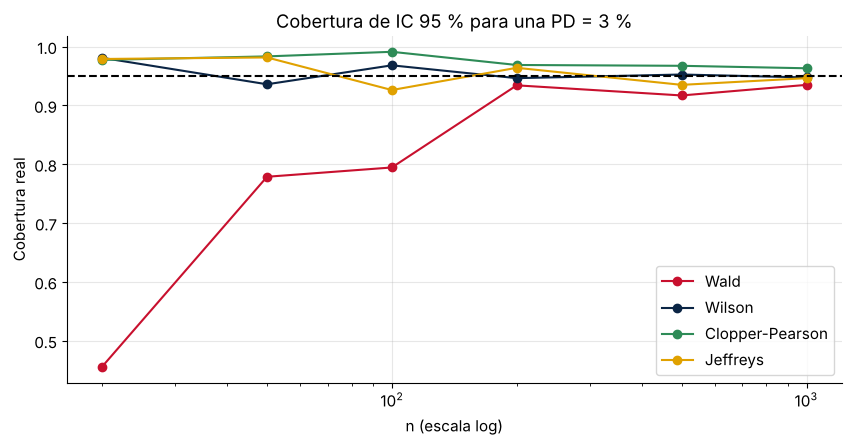

In [5]:
# Cobertura real de cada método: ¿el IC 95 % contiene a la PD verdadera el 95 % de las veces?
def cobertura(p, n, metodo, sims=5000):
    x = rng.binomial(n, p, sims)
    lo, hi = proportion_confint(x, n, alpha=0.05, method=metodo)
    return ((lo <= p) & (p <= hi)).mean()
ns = [20, 50, 100, 200, 500, 1000]
fig, ax = plt.subplots()
for m, c, lab in [("normal", ROJO, "Wald"), ("wilson", AZUL, "Wilson"), ("beta", VERDE, "Clopper-Pearson"), ("jeffreys", ORO, "Jeffreys")]:
    ax.plot(ns, [cobertura(0.03, n, m) for n in ns], marker="o", color=c, label=lab)
ax.axhline(0.95, color="black", ls="--"); ax.set_xscale("log"); ax.set_xlabel("n (escala log)"); ax.set_ylabel("Cobertura real")
ax.set_title("Cobertura de IC 95 % para una PD = 3 %"); ax.legend(); plt.show()

**Conclusión práctica:** para carteras de **bajo incumplimiento** o segmentos chicos **no uses Wald**. Wilson o Jeffreys son mejores opciones por defecto.

## 3. Ley de los grandes números, TLC y bootstrap
- **LGN:** $\hat p_n \to p$ cuando $n \to \infty$. La tasa observada converge a la PD.
- **TLC:** $\frac{\hat p_n - p}{\sqrt{p(1-p)/n}} \xrightarrow{d} N(0,1)$. Es lo que justifica los intervalos y tests basados en la normal.

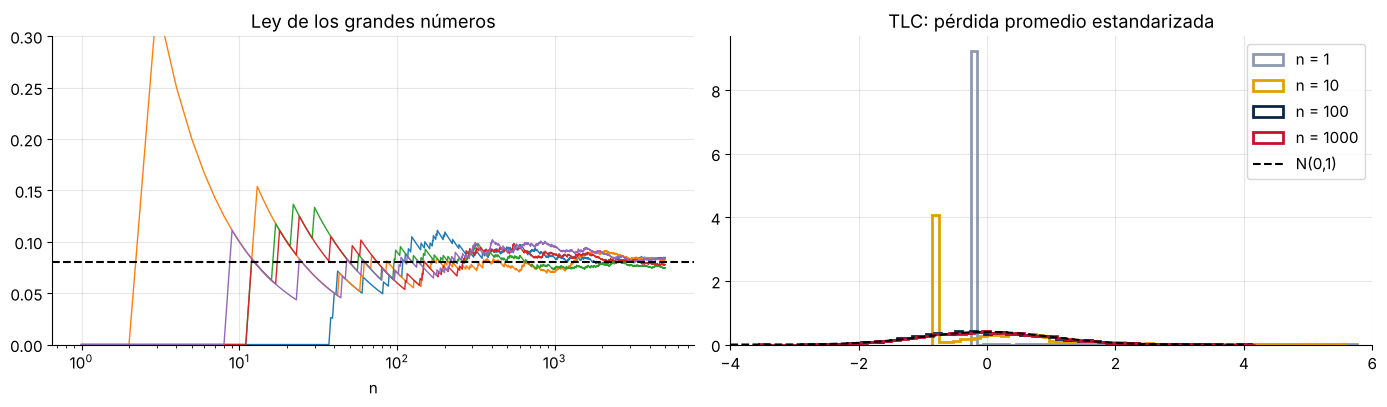

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.2))
for _ in range(5):
    d = rng.binomial(1, p_pob, 5000)
    ax[0].plot(np.arange(1, 5001), d.cumsum() / np.arange(1, 5001), lw=1)
ax[0].axhline(p_pob, color="black", ls="--"); ax[0].set_xscale("log"); ax[0].set_title("Ley de los grandes números"); ax[0].set_xlabel("n")
ax[0].set_ylim(0, .3)

# TLC: la suma de pérdidas de 'n' créditos con distribución muy asimétrica
perd_ind = lambda size: rng.binomial(1, p_pob, size) * rng.beta(2, 1.5, size)    # pérdida = default x LGD aleatoria
for n, c in [(1, GRIS), (10, ORO), (100, AZUL), (1000, ROJO)]:
    medias = perd_ind((5000, n)).mean(axis=1)
    z = (medias - medias.mean()) / medias.std()
    ax[1].hist(z, bins=60, density=True, histtype="step", lw=2, color=c, label=f"n = {n}")
xx = np.linspace(-4, 4, 200); ax[1].plot(xx, stats.norm.pdf(xx), "k--", label="N(0,1)")
ax[1].set_xlim(-4, 6); ax[1].legend(); ax[1].set_title("TLC: pérdida promedio estandarizada")
plt.tight_layout(); plt.show()

### Bootstrap: incertidumbre sin fórmula
Cuando no hay fórmula sencilla para el error estándar (p. ej., el **AUC** o el **Gini** de un modelo), remuestreamos con reemplazo.

AUC = 0.7310  IC95% bootstrap = [0.7240, 0.7378]  ->  Gini = 0.462


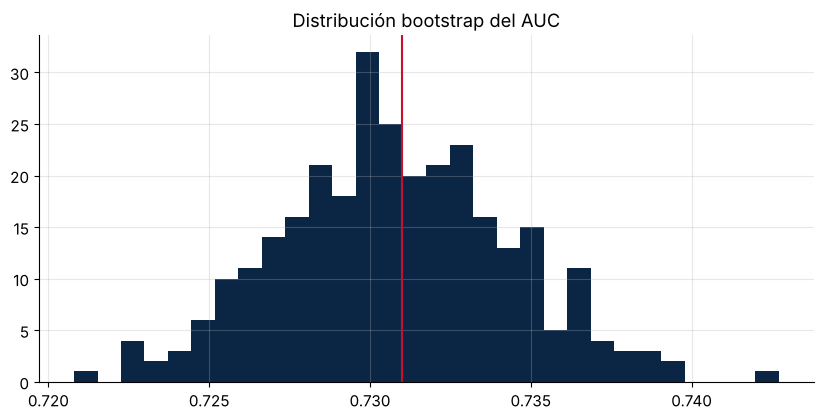

In [7]:
from sklearn.metrics import roc_auc_score
score = app[["EXT_SOURCE_2", "EXT_SOURCE_3"]].mean(axis=1).fillna(0.5)
y = app.TARGET.values
auc_obs = roc_auc_score(y, -score)
boot = []
idx = np.arange(len(y))
for _ in range(300):
    b = rng.choice(idx, len(idx), replace=True)
    boot.append(roc_auc_score(y[b], -score.values[b]))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"AUC = {auc_obs:.4f}  IC95% bootstrap = [{lo:.4f}, {hi:.4f}]  ->  Gini = {2 * auc_obs - 1:.3f}")
plt.hist(boot, bins=30, color=AZUL); plt.axvline(auc_obs, color=ROJO); plt.title("Distribución bootstrap del AUC"); plt.show()

## 4. Más intervalos: diferencia de dos PDs
¿La PD del canal digital es realmente distinta de la del canal agencia? El intervalo de **Newcombe** (combinación de dos intervalos de Wilson) se comporta mejor que el de Wald para proporciones bajas.

In [8]:
from statsmodels.stats.proportion import confint_proportions_2indep
a = app[app.CANAL == "Digital"].TARGET; b = app[app.CANAL == "Agencia"].TARGET
for metodo in ["wald", "newcomb"]:
    lo, hi = confint_proportions_2indep(a.sum(), len(a), b.sum(), len(b), method=metodo)
    print(f"{metodo:8s} PD digital − PD agencia = {a.mean() - b.mean():+.2%}  IC95 % [{lo:+.2%}, {hi:+.2%}]")

wald     PD digital − PD agencia = +1.30%  IC95 % [+0.75%, +1.85%]
newcomb  PD digital − PD agencia = +1.30%  IC95 % [+0.76%, +1.86%]


### Intervalo para una LGD promedio (variable continua y acotada)
La LGD no es una proporción binaria: es una variable continua en [0, 1], a menudo **bimodal** (muchos casos cerca de 0 y de 1). El intervalo t supone normalidad de la **media** (TLC), y conviene contrastarlo con bootstrap.

LGD promedio = 36.4% | IC t: [31.6%, 41.2%] | IC bootstrap: [31.7%, 41.3%]


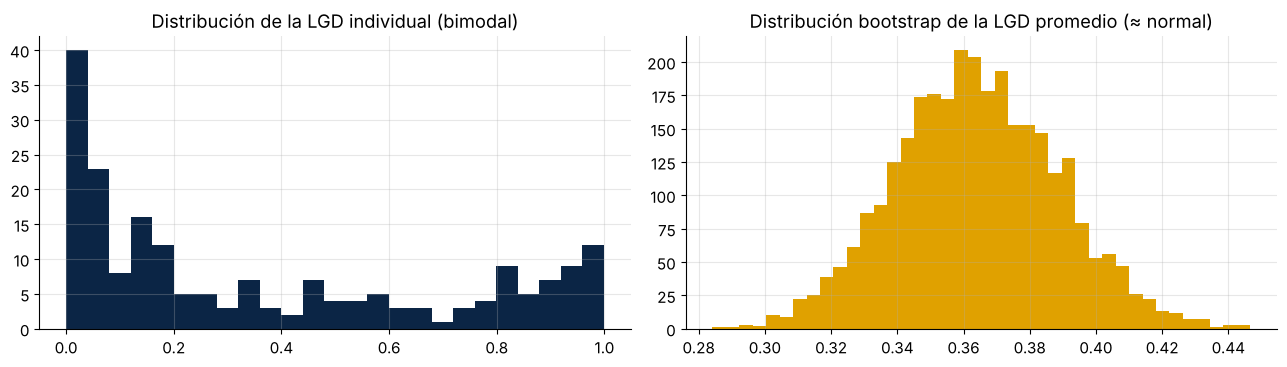

In [9]:
lgd = np.clip(np.concatenate([rng.beta(0.6, 3, 140), rng.beta(4, 0.8, 60)]), 0, 1)    # 200 casos de LGD bimodal (ilustrativo)
m, s, n = lgd.mean(), lgd.std(ddof=1), len(lgd)
t_lo, t_hi = stats.t.interval(0.95, n - 1, loc=m, scale=s / np.sqrt(n))
boot = np.array([rng.choice(lgd, n).mean() for _ in range(3000)])
b_lo, b_hi = np.percentile(boot, [2.5, 97.5])
print(f"LGD promedio = {m:.1%} | IC t: [{t_lo:.1%}, {t_hi:.1%}] | IC bootstrap: [{b_lo:.1%}, {b_hi:.1%}]")
fig, ax = plt.subplots(1, 2, figsize=(13, 3.8))
ax[0].hist(lgd, bins=25, color=AZUL); ax[0].set_title("Distribución de la LGD individual (bimodal)")
ax[1].hist(boot, bins=40, color=ORO); ax[1].set_title("Distribución bootstrap de la LGD promedio (≈ normal)")
plt.tight_layout(); plt.show()

**Lectura:** aunque cada LGD individual está lejos de la normal, la **media** sí se aproxima a ella: el TLC trabaja a nuestro favor. Por eso los intervalos t y bootstrap casi coinciden con 200 casos. Con 20 casos, no.

## 5. Tamaño de muestra para estimar una PD
Para un margen de error $E$ con confianza $1-\alpha$: $\; n = z_{1-\alpha/2}^2 \, p(1-p) / E^2$.

In [10]:
z = stats.norm.ppf(0.975)
tabla = pd.DataFrame({E: {f"PD = {p:.0%}": int(np.ceil(z ** 2 * p * (1 - p) / E ** 2)) for p in [0.01, 0.02, 0.05, 0.08, 0.15]}
                      for E in [0.0025, 0.005, 0.01, 0.02]})
tabla.columns = [f"± {E * 100:.2g} pp" for E in tabla.columns]
tabla.style.format("{:,.0f}").set_caption("Clientes necesarios para estimar la PD con el margen indicado (95 %)")

,± 0.25 pp,± 0.5 pp,± 1 pp,± 2 pp
PD = 1%,"6,085","1,522",381,96
PD = 2%,"12,047","3,012",753,189
PD = 5%,"29,196","7,299","1,825",457
PD = 8%,"45,238","11,310","2,828",707
PD = 15%,"78,366","19,592","4,898","1,225"


**Lectura:** estimar una PD de 2 % con ± 0,5 pp requiere unos 3 000 clientes; con ± 0,25 pp, más de 12 000. Esto explica por qué los segmentos pequeños se agrupan o se modelan con información compartida.

## 6. Ejercicios
1. Calcula la PD de cada `REGION_RATING_CLIENT` con sus IC de Wilson y Jeffreys. ¿Se solapan?
2. Con el intervalo de Newcombe, ¿la PD de *Retail aliado* difiere significativamente de la de *Agencia*?
3. Repite el ejercicio de la LGD con solo 20 casos. ¿Qué pasa con el intervalo t?
4. ¿Cuántos clientes necesitas para estimar una PD de 8 % con ± 1 pp al 99 %?